# Исследовательский анализ данных покрытия курьерских служб

**Задача.** Сравнить четыре сети доставки в Мексике, определить территории с выбором оператора и найти пару с наибольшим совместным охватом.

**Источник.** Лист «ДатаФрейм» книги «EDA покрытия КС.xlsx». Дата среза в книге отсутствует. В публичной версии перевозчики обозначены буквами A–D.

**Вопросы исследования**

1. Для какой доли территорий доступны две службы или больше?
2. Какая пара покрывает больше всего территорий и какие две сети сильнее всего пересекаются?
3. В каких регионах больше всего территорий с одной службой?

Работа состоит из обзора данных, предобработки, исследовательского анализа и итоговых выводов.

## 1. Загрузка и обзор данных

Путь к книге можно указать в переменной окружения `COURIER_SOURCE_XLSX` или изменить в ячейке ниже. Выводы сохранены в ноутбуке и доступны при просмотре без исходной книги.

| Поле | Что содержит |
| --- | --- |
| `POSTAL CODE` | Почтовый индекс |
| `ESTADO` | Федеральная единица Мексики |
| `MUNICIPIO` | Муниципалитет или район |
| `КС` | Служба, указанная в записи |

In [1]:
from itertools import combinations
from pathlib import Path
from string import ascii_uppercase
import os

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
import pandas as pd
from IPython.display import Markdown, display

%matplotlib inline

source_path = Path(os.getenv("COURIER_SOURCE_XLSX", "data/EDA покрытия КС.xlsx"))
if not source_path.is_file():
    raise FileNotFoundError(
        "Укажите путь к исходной книге в source_path или COURIER_SOURCE_XLSX."
    )

def read_source(path):
    columns = {
        "POSTAL CODE": "postal_code",
        "ESTADO": "region",
        "MUNICIPIO": "municipality",
        "КС": "carrier",
    }
    frame = pd.read_excel(
        path, sheet_name="ДатаФрейм", usecols=list(columns),
        dtype="string", keep_default_na=False, engine="openpyxl",
    ).rename(columns=columns)
    for column in frame:
        frame[column] = (
            frame[column].str.normalize("NFC").str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )
    valid = frame["postal_code"].str.fullmatch(r"[0-9]{1,5}") & frame["carrier"].ne("")
    original_labels = frame.loc[valid, "carrier"].drop_duplicates()
    if len(original_labels) > len(ascii_uppercase):
        raise ValueError("Для числа служб в книге требуется расширить алфавит.")
    labels = {label: f"Служба {letter}" for label, letter in zip(original_labels, ascii_uppercase)}
    frame["carrier"] = frame["carrier"].map(labels).astype("string")
    return frame

source = read_source(source_path)

In [2]:
placeholders = {"", "-", "Нет"}
profile = pd.DataFrame({
    "Тип данных": source.dtypes.astype(str),
    "Пропуски и заполнители": (source.isna() | source.isin(placeholders)).sum(),
}).rename(index={
    "postal_code": "Почтовый индекс",
    "region": "Регион",
    "municipality": "Муниципалитет",
    "carrier": "Служба",
})
print(f"Строк: {len(source):,}. Служб: {source['carrier'].nunique()}.".replace(",", " "))
display(profile)

Строк: 157 955. Служб: 4.


,Тип данных,Пропуски и заполнители
Почтовый индекс,string,0
Регион,string,321
Муниципалитет,string,31553
Служба,string,0


В книге **157 955 записей**. Сочетание индекса и службы может повторяться для нескольких районов. У одной службы поле муниципалитета систематически заполнено значением «Нет», поэтому анализ на этом уровне дал бы несопоставимые результаты.

## 2. Предобработка

Единица анализа — **почтовый индекс × регион**. Один оператор учитывается на такой территории один раз. Индекс храним как строку, чтобы сохранить ведущие нули.

In [3]:
region_aliases = {'Aguas Caclientes': 'Aguascalientes',
 'Baja California Norte': 'Baja California',
 'CDMX': 'Ciudad de México',
 'Ciudad de Mexico': 'Ciudad de México',
 'Coahuila de Zaragoza': 'Coahuila',
 'Estado de Mexico (Metropolitana)': 'Estado de México',
 'Estado de Mexico (Toluca)': 'Estado de México',
 'México': 'Estado de México',
 'Michoacan': 'Michoacán',
 'Michoacán de Ocampo': 'Michoacán',
 'NuevoLeon': 'Nuevo León',
 'Queretaro': 'Querétaro',
 'San Luis Potosi': 'San Luis Potosí',
 'Veracruz de Ignacio de la Llave': 'Veracruz',
 'Yucatan': 'Yucatán'}


valid_postal = source["postal_code"].str.fullmatch(r"[0-9]{1,5}").fillna(False)
valid = valid_postal & source["carrier"].notna()
clean = source.loc[valid, ["postal_code", "region", "carrier"]].copy()
padded_rows = clean["postal_code"].str.len().lt(5).sum()
clean["postal_code"] = clean["postal_code"].str.zfill(5)
clean["region"] = clean["region"].replace(region_aliases).replace({"": pd.NA, "-": pd.NA})

# Строим соответствие только там, где один индекс связан с одним известным регионом.
known_regions = clean.dropna(subset=["region"])[["postal_code", "region"]].drop_duplicates()
region_count = known_regions.groupby("postal_code")["region"].size()
unique_region = (
    known_regions.loc[known_regions["postal_code"].map(region_count).eq(1)]
    .set_index("postal_code")["region"]
)
missing_region = clean["region"].isna()
clean.loc[missing_region, "region"] = clean.loc[missing_region, "postal_code"].map(unique_region)
inferred_rows = (missing_region & clean["region"].notna()).sum()
named = clean.dropna(subset=["region"])

keys = ["region", "postal_code"]
coverage = named.drop_duplicates(keys + ["carrier"])
preparation = pd.Series({
    "Непригодных индексов или служб": (~valid).sum(),
    "Строк с добавленными ведущими нулями": padded_rows,
    "Строк с восстановленным регионом": inferred_rows,
    "Строк без региона после восстановления": clean["region"].isna().sum(),
    "Повторных связей территории и службы": len(named) - len(coverage),
    "Уникальных связей территории и службы": len(coverage),
}, name="Строк")
display(preparation.to_frame())

,Строк
Непригодных индексов или служб,0
Строк с добавленными ведущими нулями,1643
Строк с восстановленным регионом,219
Строк без региона после восстановления,102
Повторных связей территории и службы,100225
Уникальных связей территории и службы,57628


После очистки осталось **57 628** уникальных связей территории и службы. Для 219 записей регион восстановлен по другим строкам с тем же индексом. Ещё 102 записи без региона участвуют в отдельной проверке по индексу.

## 3. Исследовательский анализ

### 3.1. Сколько служб указано для одной территории

Считаем число уникальных служб для каждой территории. Доли рассчитываем от территорий с определённым регионом, которые присутствуют в книге.

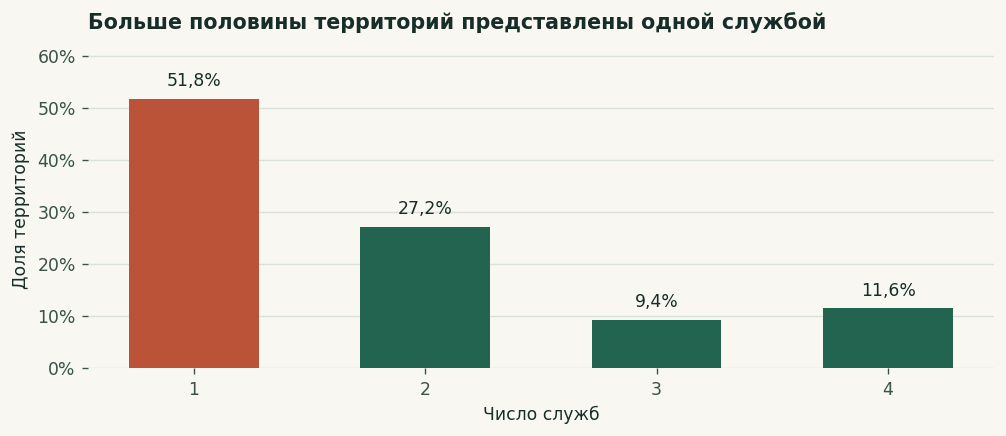

In [4]:
plt.rcParams.update({
    "figure.dpi": 124, "figure.facecolor": "#f8f7f2",
    "axes.facecolor": "#f8f7f2", "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False,
    "axes.spines.bottom": False, "text.color": "#172d2a",
    "axes.labelcolor": "#172d2a", "xtick.color": "#39524a",
    "ytick.color": "#39524a", "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlepad": 12,
})

GREEN, CORAL, INK = "#236450", "#ba5337", "#172d2a"

def fmt_n(value):
    return f"{int(value):,}".replace(",", " ")

def fmt_pct(value, precision=1):
    return f"{value:.{precision}%}".replace(".", ",")

counts = coverage.groupby(keys)["carrier"].nunique()
total = len(counts)
carrier_count = coverage["carrier"].nunique()
distribution = counts.value_counts().reindex(range(1, carrier_count + 1), fill_value=0)
distribution_share = distribution / total
multiple = counts.ge(2).sum()

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
bars = ax.bar(
    distribution.index, distribution_share,
    color=[CORAL] + [GREEN] * (carrier_count - 1), width=0.56,
)
ax.bar_label(bars, [fmt_pct(v) for v in distribution_share], padding=5, color=INK)
ax.set(
    title="Больше половины территорий представлены одной службой",
    xlabel="Число служб", ylabel="Доля территорий",
    xticks=list(distribution.index), ylim=(0, distribution_share.max() * 1.18),
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", color="#d5ded6", alpha=.85)
ax.set_axisbelow(True)
plt.show()

In [5]:
display(Markdown(
    f"Хотя бы две службы указаны для **{fmt_n(multiple)} из {fmt_n(total)}** "
    f"территорий (**{fmt_pct(multiple / total)}**). "
    f"Все четыре службы указаны для **{fmt_n(distribution.loc[carrier_count])}** территорий."
))

Хотя бы две службы указаны для **15 360 из 31 891** территорий (**48,2%**). Все четыре службы указаны для **3 697** территорий.

### 3.2. Охват операторов

Охват — число территорий, где указана служба. Эксклюзивное присутствие — территория с единственной службой в выборке.

,Охват,Только эта служба,Доля выборки
Служба D,31232,16092,"97,9%"
Служба C,13024,425,"40,8%"
Служба B,8045,1,"25,2%"
Служба A,5327,13,"16,7%"


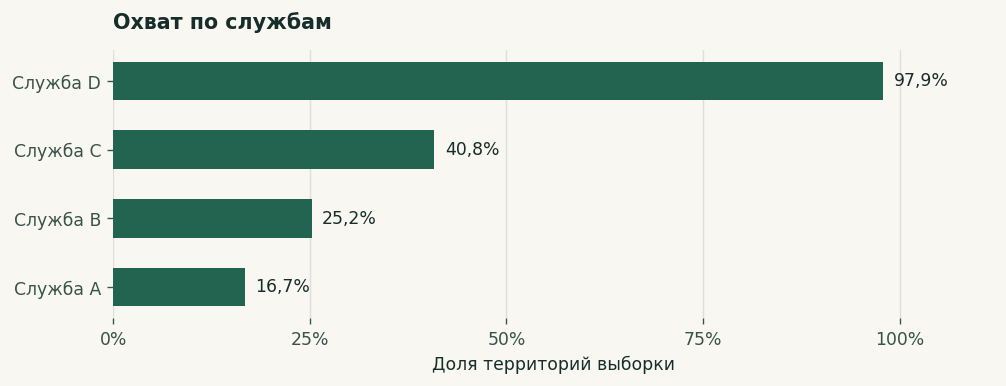

**Служба D** указана для **31 232** территорий. На **16 092** из них (50,5% основной выборки) она единственная из четырёх.

In [6]:
area_by_service = {
    carrier: set(rows[keys].itertuples(index=False, name=None))
    for carrier, rows in coverage.groupby("carrier")
}
single_areas = set(counts[counts.eq(1)].index)
services = pd.DataFrame({
    "Охват": {carrier: len(areas) for carrier, areas in area_by_service.items()},
    "Только эта служба": {
        carrier: len(areas & single_areas) for carrier, areas in area_by_service.items()
    },
}).sort_values("Охват", ascending=False)
services["Доля выборки"] = services["Охват"] / total
display(services.assign(**{"Доля выборки": services["Доля выборки"].map(fmt_pct)}))

fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
bars = ax.barh(services.index, services["Доля выборки"], color=GREEN, height=.56)
ax.bar_label(bars, services["Доля выборки"].map(fmt_pct), padding=6, color=INK)
ax.invert_yaxis()
ax.set(title="Охват по службам", xlabel="Доля территорий выборки", xlim=(0, 1.12))
ax.set_xticks([0, .25, .5, .75, 1])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", color="#d5ded6", alpha=.85)
ax.set_axisbelow(True)
plt.show()

leader = services.iloc[0]
display(Markdown(
    f"**{leader.name}** указана для **{fmt_n(leader['Охват'])}** территорий. "
    f"На **{fmt_n(leader['Только эта служба'])}** из них "
    f"({fmt_pct(leader['Только эта служба'] / total)} основной выборки) "
    "она единственная из четырёх."
))

### 3.3. Попарные пересечения

Объединение показывает, сколько территорий можно охватить хотя бы одной из двух служб. **Индекс Жаккара** равен числу общих территорий, делённому на размер объединения. Вклад второй службы — территории, которые она добавляет к охвату первой.

,Служба 1,Служба 2,Общие территории,Совместный охват,Индекс Жаккара,2-я добавляет к 1-й,1-я добавляет ко 2-й
0,Служба C,Служба D,12380,31876,"38,8%",18852,644
1,Служба B,Служба D,7840,31437,"24,9%",23392,205
2,Служба A,Служба D,5286,31273,"16,9%",25946,41
3,Служба B,Служба C,5979,15090,"39,6%",7045,2066
4,Служба A,Служба C,4120,14231,"29,0%",8904,1207
5,Служба A,Служба B,4206,9166,"45,9%",3839,1121


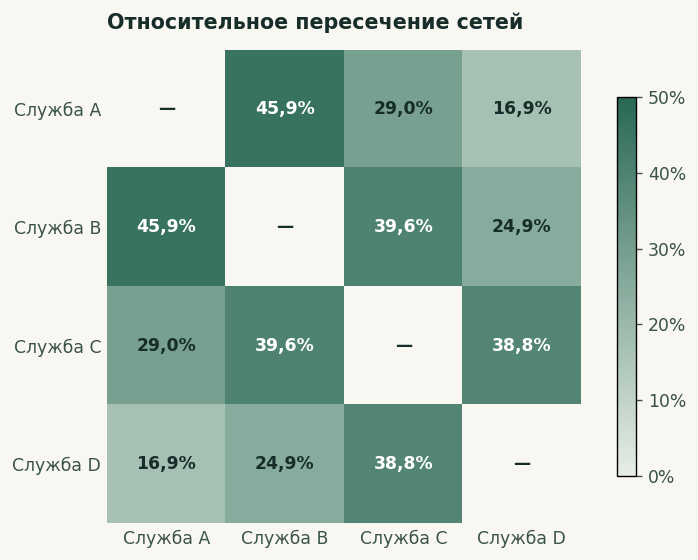

In [7]:
pair_rows = []
labels = sorted(area_by_service)
matrix = pd.DataFrame(float("nan"), index=labels, columns=labels)
for a, b in combinations(labels, 2):
    first, second = area_by_service[a], area_by_service[b]
    shared, combined = len(first & second), len(first | second)
    jaccard = shared / combined
    matrix.loc[a, b] = matrix.loc[b, a] = jaccard
    pair_rows.append({
        "Служба 1": a, "Служба 2": b, "Общие территории": shared,
        "Совместный охват": combined, "Индекс Жаккара": jaccard,
        "2-я добавляет к 1-й": len(second - first),
        "1-я добавляет ко 2-й": len(first - second),
    })
pairs = pd.DataFrame(pair_rows).sort_values("Совместный охват", ascending=False)
display(pairs.assign(**{"Индекс Жаккара": pairs["Индекс Жаккара"].map(fmt_pct)})
        .reset_index(drop=True))

cmap = LinearSegmentedColormap.from_list("coverage", ["#e7eee6", "#286853"])
cmap.set_bad("#f8f7f2")
fig, ax = plt.subplots(figsize=(6.7, 4.4), layout="constrained")
heatmap = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=.5)
ax.set(
    title="Относительное пересечение сетей",
    xticks=range(len(labels)), yticks=range(len(labels)),
    xticklabels=labels, yticklabels=labels,
)
ax.tick_params(length=0)
for i, a in enumerate(labels):
    for j, b in enumerate(labels):
        value = matrix.loc[a, b]
        text = "—" if pd.isna(value) else fmt_pct(value)
        ax.text(j, i, text, ha="center", va="center", fontweight="bold",
                color="white" if value >= .32 else INK)
fig.colorbar(heatmap, ax=ax, shrink=.8, format=PercentFormatter(1))
plt.show()

In [8]:
best = pairs.iloc[0]
most_similar = pairs.loc[pairs["Индекс Жаккара"].idxmax()]

best_pair = f"{best['Служба 1']} + {best['Служба 2']}"
similar_pair = f"{most_similar['Служба 1']} + {most_similar['Служба 2']}"
pair_names = [best["Служба 1"], best["Служба 2"]]
individual = services.loc[pair_names, "Охват"].sort_values(ascending=False)
larger, smaller = individual.index
added = best["Совместный охват"] - individual.iloc[0]

display(Markdown(
    f"**Максимальный совместный охват у пары {best_pair}.** "
    f"Это {fmt_n(best['Совместный охват'])} территорий "
    f"({fmt_pct(best['Совместный охват'] / total, 2)} выборки). "
    f"«{smaller}» добавляет {fmt_n(added)} территории к охвату «{larger}»."
))
display(Markdown(
    f"**Наибольший индекс Жаккара у пары {similar_pair}.** "
    f"Общих территорий {fmt_n(most_similar['Общие территории'])}, "
    f"индекс составляет {fmt_pct(most_similar['Индекс Жаккара'])}."
))

**Максимальный совместный охват у пары Служба C + Служба D.** Это 31 876 территорий (99,95% выборки). «Служба C» добавляет 644 территории к охвату «Служба D».

**Наибольший индекс Жаккара у пары Служба A + Служба B.** Общих территорий 4 206, индекс составляет 45,9%.

### 3.4. Доступность по регионам

Сначала ранжируем регионы по числу территорий с одной службой. Доля с двумя службами и более даёт дополнительный ракурс для сравнения регионов разного размера.

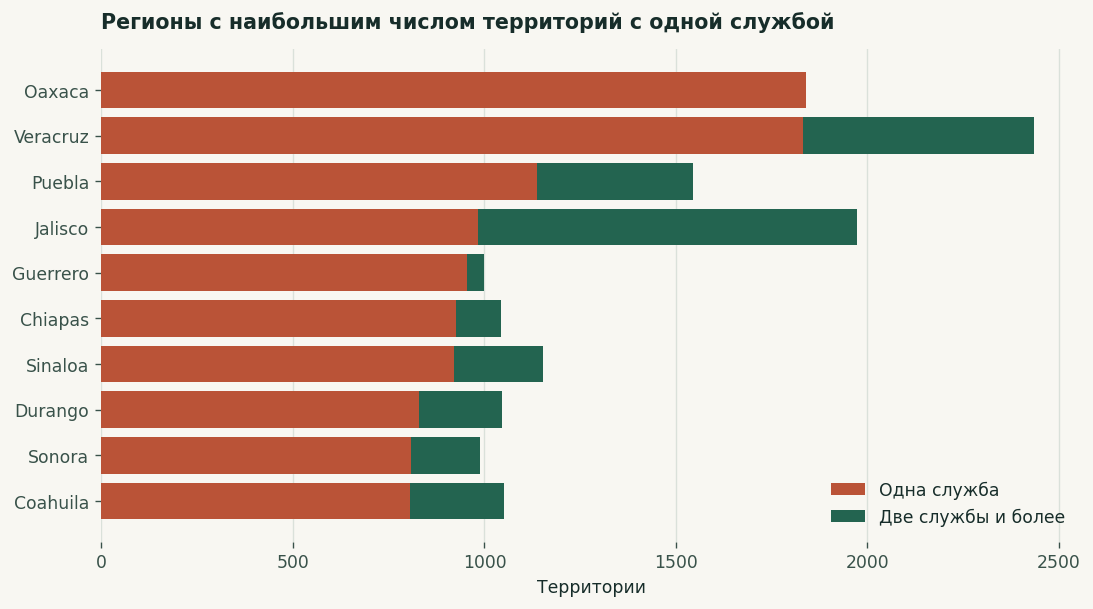

,Всего,2+ службы,1 служба,Доля 2+
region,,,,
Oaxaca,1840,0,1840,"0,0%"
Veracruz,2435,603,1832,"24,8%"
Puebla,1544,408,1136,"26,4%"
Jalisco,1974,990,984,"50,2%"
Guerrero,998,44,954,"4,4%"
Chiapas,1042,117,925,"11,2%"
Sinaloa,1153,232,921,"20,1%"
Durango,1047,218,829,"20,8%"
Sonora,988,180,808,"18,2%"


In [9]:
regions = (
    counts.to_frame("carriers")
    .assign(multiple=lambda x: x["carriers"].ge(2))
    .groupby(level="region").agg(zones=("carriers", "size"), multi=("multiple", "sum"))
)
regions["single"] = regions["zones"] - regions["multi"]
regions["multi_share"] = regions["multi"] / regions["zones"]
regions = regions.sort_values(["single", "zones"], ascending=False)
region_top = regions.head(10)

fig, ax = plt.subplots(figsize=(8.7, 4.8), layout="constrained")
ax.barh(region_top.index, region_top["single"], color=CORAL, label="Одна служба")
ax.barh(region_top.index, region_top["multi"], left=region_top["single"],
        color=GREEN, label="Две службы и более")
ax.invert_yaxis()
ax.set(title="Регионы с наибольшим числом территорий с одной службой", xlabel="Территории")
ax.grid(axis="x", color="#d5ded6", alpha=.85)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False)
plt.show()

display(region_top.assign(multi_share=region_top["multi_share"].map(fmt_pct))
        .rename(columns={"zones": "Всего", "multi": "2+ службы", "single": "1 служба",
                         "multi_share": "Доля 2+"}))

В **Oaxaca** одна служба указана для всех **1 840** территорий выборки. В **Veracruz** таких территорий **1 832 из 2 435**. Эти регионы дают больше всего наблюдений для проверки, где появление второго оператора расширило бы выбор.

## 4. Проверка чувствительности

Сравним три варианта группировки. Сначала сменим только ключ. Затем включим записи, для которых регион не удалось восстановить.

In [10]:
postal_named = coverage.groupby("postal_code")["carrier"].nunique()
postal_all = clean.groupby("postal_code")["carrier"].nunique()
versions = {
    "Индекс и регион": counts,
    "Индекс, только записи с регионом": postal_named,
    "Индекс, все пригодные записи": postal_all,
}
sensitivity = pd.DataFrame.from_dict({
    label: {"Территории": len(values), "2+ службы": values.ge(2).sum(),
            "Доля 2+": fmt_pct(values.ge(2).mean())}
    for label, values in versions.items()
}, orient="index")
assert distribution.sum() == total == regions["zones"].sum()
assert distribution.mul(distribution.index).sum() == len(coverage) == services["Охват"].sum()
assert multiple == regions["multi"].sum()
assert (pairs["Совместный охват"] == pairs["Общие территории"] +
        pairs["2-я добавляет к 1-й"] + pairs["1-я добавляет ко 2-й"]).all()
display(sensitivity)

,Территории,2+ службы,Доля 2+
Индекс и регион,31891,15360,"48,2%"
"Индекс, только записи с регионом",31891,15360,"48,2%"
"Индекс, все пригодные записи",31993,15360,"48,0%"


На одном наборе строк обе единицы анализа дают одинаковое число территорий и одинаковую долю с выбором. Добавление записей без региона увеличивает знаменатель до **31 993** индексов. Число индексов с двумя службами и более остаётся **15 360**, доля составляет **48,0%**.

## 5. Выводы

1. **Для 48,2% территорий указаны две службы или больше.** На 16 531 территории указана одна служба. Из них 16 092 представлены службой D.
2. **Службы C и D вместе охватывают 31 876 территорий, или 99,95% выборки с известным регионом.** Служба C добавляет к покрытию D 644 территории. Максимальный индекс Жаккара у служб A и B — 45,9%.
3. **Oaxaca и Veracruz лидируют по числу территорий с одной службой.** При поиске резервного партнёра эти регионы дают больше всего территорий для дальнейшей проверки.

**Ограничения.** Проценты относятся к выгрузке. Для оценки доли от всех индексов Мексики нужен полный справочник. Книга не содержит объёмов заказов, тарифов, сроков и подтверждённых результатов доставок. При оценке операционной выгоды эти показатели нужно рассматривать вместе с охватом.